# Duka Electronics: H1 2026 Board Report

*One-page visual report for the Duka Electronics board · PLP Data Analytics, Assignment 6*

---
## 1. Storyboard (written before any plotting code)

| | |
|---|---|
| **Audience** | The Duka Electronics board: non-technical, short on time, reading on their **phones** before next week's meeting. |
| **Decision they own** | **Where to focus sales effort and budget in the second half of 2026 (H2).** |
| **Big Idea** | *Duka's revenue rides on three big-ticket products. In H2, push them hardest where they are under-sold: Nakuru.* |

### SCR: Situation, Complication, Resolution

1. **Situation.** Duka Electronics earned **KES 30.8M from 1,000 orders** in H1 2026, and **68%** of it came from just three big-ticket products: Laptop 15in, Smartphone and Smart TV 55in.
2. **Complication.** Growth has stalled: **Q2 closed 7% below Q1**, and **Nakuru's average order is KES 8.8K (27%) lower** than the other four branches because few of its customers buy big-ticket items.
3. **Resolution.** In H2 make big-ticket products the priority: lift Nakuru's average order to the peer level (**about KES 1.4M per half-year**) and keep Nairobi and Mombasa fully stocked.

### Chart plan: each chart is one step in proving the Big Idea

| # | Chart | Type | What it proves |
|---|---|---|---|
| 1 | Monthly revenue, Jan to Jun | **Trend** (line) | Revenue peaked in March and has not recovered (the complication) |
| 2 | Revenue by product | **Comparison** (sorted bars) | Three products dominate revenue (the situation) |
| 3 | Share of orders vs share of revenue | **Composition** (100% bars) | The same three products are a minority of orders but a majority of revenue |
| 4 | Order value | **Distribution** (histogram) | A small number of large orders decides the result |
| 5 | Average order value by branch | **Comparison** (sorted bars) | Nakuru is the gap, so it is where H2 effort pays most (the resolution) |

### Design rules applied to every chart
Sorted bars · **one highlight colour** (orange) against neutral grey · direct labels instead of legends · no gridlines, boxes or tick clutter · **insight titles calculated in code** · units on every axis · a source line under every chart · large type for phone reading.

## 2. Setup, load and clean the data
Reusing `duka_sales.csv` from Week 3 (1,000 orders, Jan to Jun 2026). Dates in the file are `DD/MM/YYYY`, so they are parsed with an explicit format.

In [1]:
from pathlib import Path
import textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

Path("reports").mkdir(exist_ok=True)
Path("figures").mkdir(exist_ok=True)
Path("data").mkdir(exist_ok=True)

raw = pd.read_csv("data/duka_sales.csv")
print(f"Loaded {raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head()

Loaded 1,000 rows x 7 columns


,order_id,order_date,branch,product,channel,units,unit_price
0,DK0001,01/01/2026,Nakuru,Wireless Earbuds,In-store,1,6500
1,DK0002,01/01/2026,Nakuru,Bluetooth Speaker,Online,1,9500
2,DK0003,01/01/2026,Nairobi,Smartphone,In-store,2,22000
3,DK0004,01/01/2026,Nairobi,Tablet,In-store,3,18000
4,DK0005,02/01/2026,Kisumu,Microwave,Online,1,15000


In [2]:
df = raw.copy()
df["order_date"] = pd.to_datetime(df["order_date"], format="%d/%m/%Y")   # file uses DD/MM/YYYY

# Derived columns (same definitions as Assignment 3)
df["revenue"] = df["units"] * df["unit_price"]            # KES
df["month"]   = df["order_date"].dt.to_period("M")
df["quarter"] = df["order_date"].dt.quarter

# ---- data-quality checks (all must pass before we trust any chart) ----
checks = {
    "no missing values":            df.isna().sum().sum() == 0,
    "order_id is unique":           df["order_id"].is_unique,
    "all dates inside Jan-Jun 2026": df["order_date"].between("2026-01-01", "2026-06-30").all(),
    "units and prices positive":    ((df["units"] > 0) & (df["unit_price"] > 0)).all(),
}
for name, ok in checks.items():
    print(("PASS  " if ok else "FAIL  ") + name)
assert all(checks.values())

df.head()

PASS  no missing values
PASS  order_id is unique
PASS  all dates inside Jan-Jun 2026
PASS  units and prices positive


,order_id,order_date,branch,product,channel,units,unit_price,revenue,month,quarter
0,DK0001,2026-01-01,Nakuru,Wireless Earbuds,In-store,1,6500,6500,2026-01,1
1,DK0002,2026-01-01,Nakuru,Bluetooth Speaker,Online,1,9500,9500,2026-01,1
2,DK0003,2026-01-01,Nairobi,Smartphone,In-store,2,22000,44000,2026-01,1
3,DK0004,2026-01-01,Nairobi,Tablet,In-store,3,18000,54000,2026-01,1
4,DK0005,2026-01-02,Kisumu,Microwave,Online,1,15000,15000,2026-01,1


### Defining "big-ticket" in code
Rather than hard-coding product names, the **three products with the highest H1 revenue** are identified from the data and flagged. Everything downstream (titles, colours, labels) reads from this list.

In [3]:
prod_rev = df.groupby("product")["revenue"].sum().sort_values(ascending=False)
TOP3 = list(prod_rev.head(3).index)                       # ['Laptop 15in', 'Smartphone', 'Smart TV 55in']
df["price_band"] = np.where(df["product"].isin(TOP3), "Big-ticket", "Other")

def join_names(names):
    return ", ".join(names[:-1]) + " and " + names[-1]

print("Big-ticket products:", join_names(TOP3))

Big-ticket products: Laptop 15in, Smartphone and Smart TV 55in


### Every number used in the report, calculated once
All insight titles, KPI cards and the written summary read from this one dictionary, so the story can never drift away from the data.

In [4]:
total   = df["revenue"].sum()
n_ord   = len(df)
monthly = df.groupby("month")["revenue"].sum()
q       = df.groupby("quarter")["revenue"].sum()
q_chg   = (q[2] - q[1]) / q[1] * 100                         # Q2 vs Q1, %

big_rev_share    = df.loc[df.price_band == "Big-ticket", "revenue"].sum() / total * 100
big_order_share  = (df.price_band == "Big-ticket").mean() * 100

branch = df.groupby("branch").agg(rev=("revenue", "sum"), n=("order_id", "count"))
branch["aov"] = branch["rev"] / branch["n"]
weak_branch   = branch["aov"].idxmin()                       # lowest average order value
others        = branch.drop(index=weak_branch)
others_aov    = others["rev"].sum() / others["n"].sum()      # order-weighted average of the other 4
aov_gap       = others_aov - branch.loc[weak_branch, "aov"]
uplift        = aov_gap * branch.loc[weak_branch, "n"]       # if weak branch matched peers, same order count

weak_big_share = (df[df.branch == weak_branch].price_band == "Big-ticket").mean() * 100
nm_share = branch.loc[["Nairobi", "Mombasa"], "rev"].sum() / total * 100

K = dict(
    total=total, orders=n_ord, aov=total / n_ord,
    peak_month=monthly.idxmax().strftime("%B"), peak_value=monthly.max(),
    q1=q[1], q2=q[2], q_chg=q_chg,
    top3=TOP3, big_rev_share=big_rev_share, big_order_share=big_order_share,
    weak_branch=weak_branch, weak_aov=branch.loc[weak_branch, "aov"], others_aov=others_aov,
    aov_gap=aov_gap, aov_gap_pct=aov_gap / others_aov * 100, uplift=uplift,
    weak_big_share=weak_big_share, nairobi_mombasa_share=nm_share,
    median_order=df["revenue"].median(),
)
pd.Series({k: (round(v, 2) if isinstance(v, float) else v) for k, v in K.items()})

total                                                    30755900
orders                                                       1000
aov                                                       30755.9
peak_month                                                  March
peak_value                                                6405800
q1                                                       15943400
q2                                                       14812500
q_chg                                                       -7.09
top3                     [Laptop 15in, Smartphone, Smart TV 55in]
big_rev_share                                               68.39
big_order_share                                              37.6
weak_branch                                                Nakuru
weak_aov                                                 23375.32
others_aov                                               32140.86
aov_gap                                                   8765.54
aov_gap_pc

### Storyboard check
The SCR sentences above contain numbers. This cell fails loudly if any of them stops matching the data.

In [5]:
assert round(K["total"] / 1e6, 1) == 30.8 and K["orders"] == 1000
assert round(K["big_rev_share"]) == 68
assert round(K["q_chg"]) == -7
assert K["weak_branch"] == "Nakuru" and round(K["aov_gap"] / 1000, 1) == 8.8 and round(K["aov_gap_pct"]) == 27
assert round(K["uplift"] / 1e6, 1) == 1.4
print("Storyboard numbers all match the data.")

Storyboard numbers all match the data.


## 3. Design system
One highlight colour, neutral greys for everything else, and a small set of helpers so every chart gets the same **insight title, units and source line**.

In [6]:
HIGHLIGHT = "#E8590C"     # the ONE accent colour: "look here"
GREY      = "#B4B9C0"     # everything else
DARK      = "#1F2933"     # titles and labels
MID       = "#5F6B76"     # axis text and source lines

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 11,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#9AA3AD", "axes.labelcolor": MID,
    "xtick.color": MID, "ytick.color": MID, "axes.grid": False,
})

W = 8.0                      # figure width in inches (portrait, phone-friendly)
TITLE_H, FOOT_H = 0.75, 1.0 # space reserved above / below each plot, in inches
X_TEXT = 0.35 / W            # left edge of titles and source lines (figure fraction)
SOURCE = f"Source: Duka Electronics sales ledger, Jan-Jun 2026 ({len(df):,} orders). KES = Kenya shillings."

def panel_height(plot_h):
    return TITLE_H + plot_h + FOOT_H

def add_panel(fig, top, plot_h, left):
    """Place a plot area `top` inches below the top of the figure; room is left for an insight title above and a source line below."""
    H = fig.get_figheight()
    return fig.add_axes([left / W, 1 - (top + TITLE_H + plot_h) / H, (W - left - 0.45) / W, plot_h / H])

def insight_title(ax, text, width=62):
    ax.annotate(textwrap.fill(text, width), xy=(X_TEXT, 1), xycoords=("figure fraction", "axes fraction"),
                xytext=(0, 14), textcoords="offset points", ha="left", va="bottom",
                fontsize=13.5, fontweight="bold", color=DARK, linespacing=1.25)

def source_line(ax, dy=-50):
    ax.annotate(SOURCE, xy=(X_TEXT, 0), xycoords=("figure fraction", "axes fraction"),
                xytext=(0, dy), textcoords="offset points", ha="left", va="top", fontsize=8, color=MID)

def kes_m(v): return f"KES {v/1e6:.1f}M"
def kes_k(v): return f"KES {v/1e3:.1f}K"

## 4. The five charts
Each chart is a function that draws onto a given axis, so the **same code** is used here (one chart at a time) and in the one-page layout in section 5. Titles are f-strings fed by the numbers calculated above.

### Chart 1: Trend. Monthly revenue

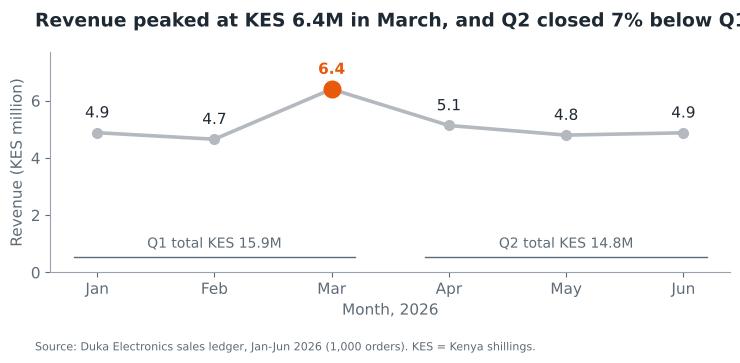

In [7]:
def chart_trend(ax):
    labels = [p.strftime("%b") for p in monthly.index]
    x, y = np.arange(len(monthly)), monthly.values / 1e6
    ip = int(np.argmax(y))

    ax.plot(x, y, color=GREY, lw=2.6, marker="o", ms=7, zorder=2)
    ax.plot(x[ip], y[ip], "o", ms=12, color=HIGHLIGHT, zorder=3)
    for i, v in enumerate(y):                              # direct labels on every point
        ax.annotate(f"{v:.1f}", (x[i], v), xytext=(0, 11), textcoords="offset points", ha="center",
                    fontsize=11, fontweight="bold" if i == ip else "normal",
                    color=HIGHLIGHT if i == ip else DARK)

    # quarter totals as quiet reference brackets along the bottom
    for xs, xe, lab in [(0, 2, f"Q1 total {kes_m(K['q1'])}"), (3, 5, f"Q2 total {kes_m(K['q2'])}")]:
        ax.plot([xs - .2, xe + .2], [0.55, 0.55], color=MID, lw=1)
        ax.text((xs + xe) / 2, 0.75, lab, ha="center", va="bottom", fontsize=10, color=MID)

    ax.set_xticks(x, labels)
    ax.set_ylim(0, y.max() * 1.2)
    ax.set_xlim(-0.4, len(x) - 0.6)
    ax.set_xlabel("Month, 2026")
    ax.set_ylabel("Revenue (KES million)")
    direction = "below" if K["q_chg"] < 0 else "above"
    insight_title(ax, f"Revenue peaked at {kes_m(K['peak_value'])} in {K['peak_month']}, "
                      f"and Q2 closed {abs(K['q_chg']):.0f}% {direction} Q1")
    source_line(ax)

PANELS = {}                    # name -> (function, plot height in inches, left margin in inches)
PANELS["trend"] = (chart_trend, 2.2, 0.75)

def show_chart(name):
    fn, h, left = PANELS[name]
    fig = plt.figure(figsize=(W, panel_height(h)))
    fn(add_panel(fig, 0, h, left))
    plt.show()

show_chart("trend")

### Chart 2: Comparison. Revenue by product (sorted bars)

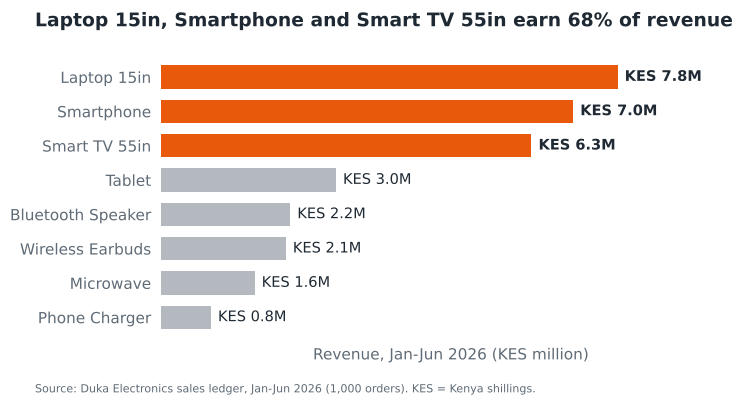

In [8]:
def chart_products(ax):
    p = df.groupby("product")["revenue"].sum().sort_values()           # ascending -> largest bar on top
    is_top = [name in TOP3 for name in p.index]
    ax.barh(p.index, p.values / 1e6, height=0.68, color=[HIGHLIGHT if t else GREY for t in is_top])
    for i, (v, t) in enumerate(zip(p.values, is_top)):                 # direct labels
        ax.text(v / 1e6 + 0.12, i, kes_m(v), va="center", fontsize=10.5,
                fontweight="bold" if t else "normal", color=DARK)
    ax.set_xlim(0, p.max() / 1e6 * 1.27)
    ax.set_xticks([])
    ax.tick_params(left=False)
    ax.spines[["left", "bottom"]].set_visible(False)
    ax.set_xlabel("Revenue, Jan-Jun 2026 (KES million)")
    insight_title(ax, f"{join_names(TOP3)} earn {K['big_rev_share']:.0f}% of revenue")
    source_line(ax, dy=-30)

PANELS["products"] = (chart_products, 2.9, 1.75)
show_chart("products")

### Chart 3: Composition. Share of orders vs share of revenue

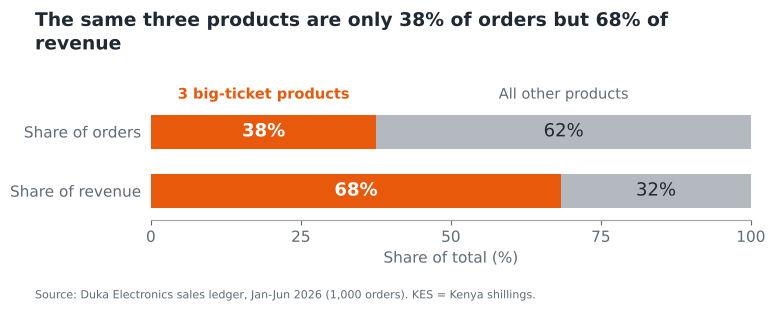

In [9]:
def chart_composition(ax):
    rows = [("Share of revenue", K["big_rev_share"]), ("Share of orders", K["big_order_share"])]
    for i, (lab, big) in enumerate(rows):
        ax.barh(i, big, color=HIGHLIGHT, height=0.58)
        ax.barh(i, 100 - big, left=big, color=GREY, height=0.58)
        ax.text(big / 2, i, f"{big:.0f}%", ha="center", va="center", color="white", fontsize=13, fontweight="bold")
        ax.text(big + (100 - big) / 2, i, f"{100 - big:.0f}%", ha="center", va="center", color=DARK, fontsize=13)
    # direct labels replace a legend
    ax.text(K["big_order_share"] / 2, 1.5, f"{len(TOP3)} big-ticket products", ha="center", va="bottom",
            fontsize=10.5, fontweight="bold", color=HIGHLIGHT)
    ax.text(K["big_order_share"] + (100 - K["big_order_share"]) / 2, 1.5, "All other products", ha="center",
            va="bottom", fontsize=10.5, color=MID)
    ax.set_yticks([0, 1], [r[0] for r in rows])
    ax.set_ylim(-0.5, 1.95)
    ax.set_xlim(0, 100)
    ax.set_xticks([0, 25, 50, 75, 100])
    ax.set_xlabel("Share of total (%)")
    ax.tick_params(left=False)
    ax.spines[["left"]].set_visible(False)
    insight_title(ax, f"The same three products are only {K['big_order_share']:.0f}% of orders "
                      f"but {K['big_rev_share']:.0f}% of revenue")
    source_line(ax)

PANELS["composition"] = (chart_composition, 1.45, 1.55)
show_chart("composition")

### Chart 4: Distribution. How big is a typical order?

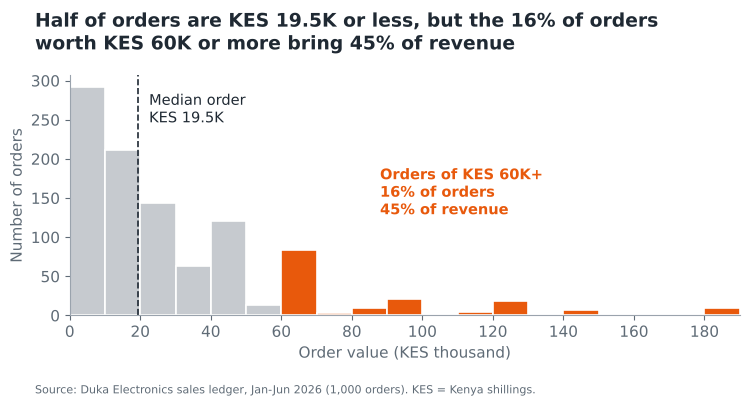

In [10]:
LARGE = 60_000                                             # "large order" threshold, KES
large      = df["revenue"] >= LARGE
large_n    = large.mean() * 100                            # % of orders
large_rev  = df.loc[large, "revenue"].sum() / total * 100  # % of revenue

def chart_distribution(ax):
    s = df["revenue"] / 1000
    bins = np.arange(0, 200, 10)
    sns.histplot(s, bins=bins, color=GREY, edgecolor="white", linewidth=1.2, ax=ax)
    for patch in ax.patches:                               # highlight the large-order bins
        if patch.get_x() >= LARGE / 1000:
            patch.set_facecolor(HIGHLIGHT)
    med = s.median()
    ax.axvline(med, color=DARK, ls="--", lw=1.2)
    ax.text(med + 3, ax.get_ylim()[1] * 0.93, f"Median order\n{kes_k(med * 1000)}", fontsize=10.5, color=DARK, va="top")
    ax.text(88, ax.get_ylim()[1] * 0.62,
            f"Orders of KES {LARGE // 1000}K+\n{large_n:.0f}% of orders\n{large_rev:.0f}% of revenue",
            fontsize=10.5, color=HIGHLIGHT, fontweight="bold", va="top")
    ax.set_xlim(0, 190)
    ax.set_xticks(range(0, 200, 20))
    ax.set_xlabel("Order value (KES thousand)")
    ax.set_ylabel("Number of orders")
    insight_title(ax, f"Half of orders are KES {K['median_order'] / 1000:.1f}K or less, but the "
                      f"{large_n:.0f}% of orders worth KES {LARGE // 1000}K or more bring {large_rev:.0f}% of revenue")
    source_line(ax)

PANELS["distribution"] = (chart_distribution, 2.4, 0.85)
show_chart("distribution")

### Chart 5: Comparison. Average order value by branch (the resolution)

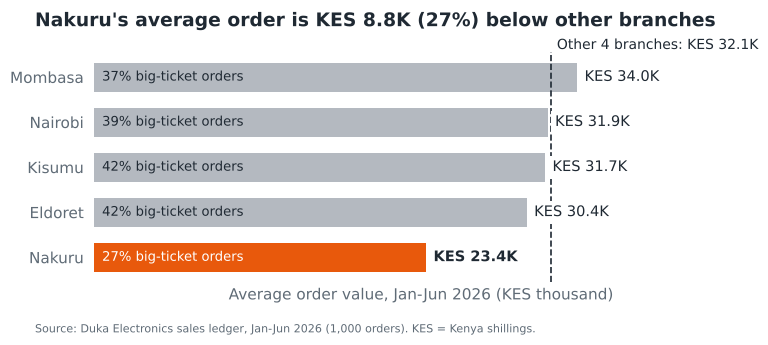

In [11]:
def chart_branch_aov(ax):
    g = branch.sort_values("aov")                          # ascending -> largest on top
    big_share = df.groupby("branch")["price_band"].apply(lambda s: (s == "Big-ticket").mean() * 100)
    weak = [b == K["weak_branch"] for b in g.index]
    ax.barh(g.index, g["aov"] / 1e3, height=0.64, color=[HIGHLIGHT if w else GREY for w in weak])
    for i, (b, v, w) in enumerate(zip(g.index, g["aov"], weak)):
        ax.text(v / 1e3 + 0.5, i, kes_k(v), va="center", fontsize=10.5, zorder=5,
                fontweight="bold" if w else "normal", color=DARK,
                bbox=dict(fc="white", ec="none", pad=3))
        ax.text(0.6, i, f"{big_share[b]:.0f}% big-ticket orders", va="center", fontsize=9.5,
                color="white" if w else DARK)
    ax.axvline(K["others_aov"] / 1e3, color=DARK, ls="--", lw=1.2, zorder=1)
    ax.text(K["others_aov"] / 1e3 + 0.4, len(g) - 0.45, f"Other {len(g) - 1} branches: {kes_k(K['others_aov'])}",
            fontsize=10, color=DARK, va="bottom")
    ax.set_xlim(0, 46)
    ax.set_xticks([])
    ax.tick_params(left=False)
    ax.spines[["left", "bottom"]].set_visible(False)
    ax.set_xlabel("Average order value, Jan-Jun 2026 (KES thousand)")
    insight_title(ax, f"{K['weak_branch']}'s average order is {kes_k(K['aov_gap'])} ({K['aov_gap_pct']:.0f}%) "
                      f"below other branches")
    source_line(ax, dy=-30)

PANELS["branch"] = (chart_branch_aov, 2.3, 1.0)
show_chart("branch")

## 5. The one-page report
A single portrait figure, **8 in wide and saved at 200 dpi (1,600 px)**, so it can be read by scrolling on a phone without zooming. Order of the page follows the SCR: headline and KPIs, then charts 1 to 5, then the H2 recommendation.

Saved reports/duka_board_report.png  (8 x 25.6 in at 200 dpi = 1600 x 5110 px)


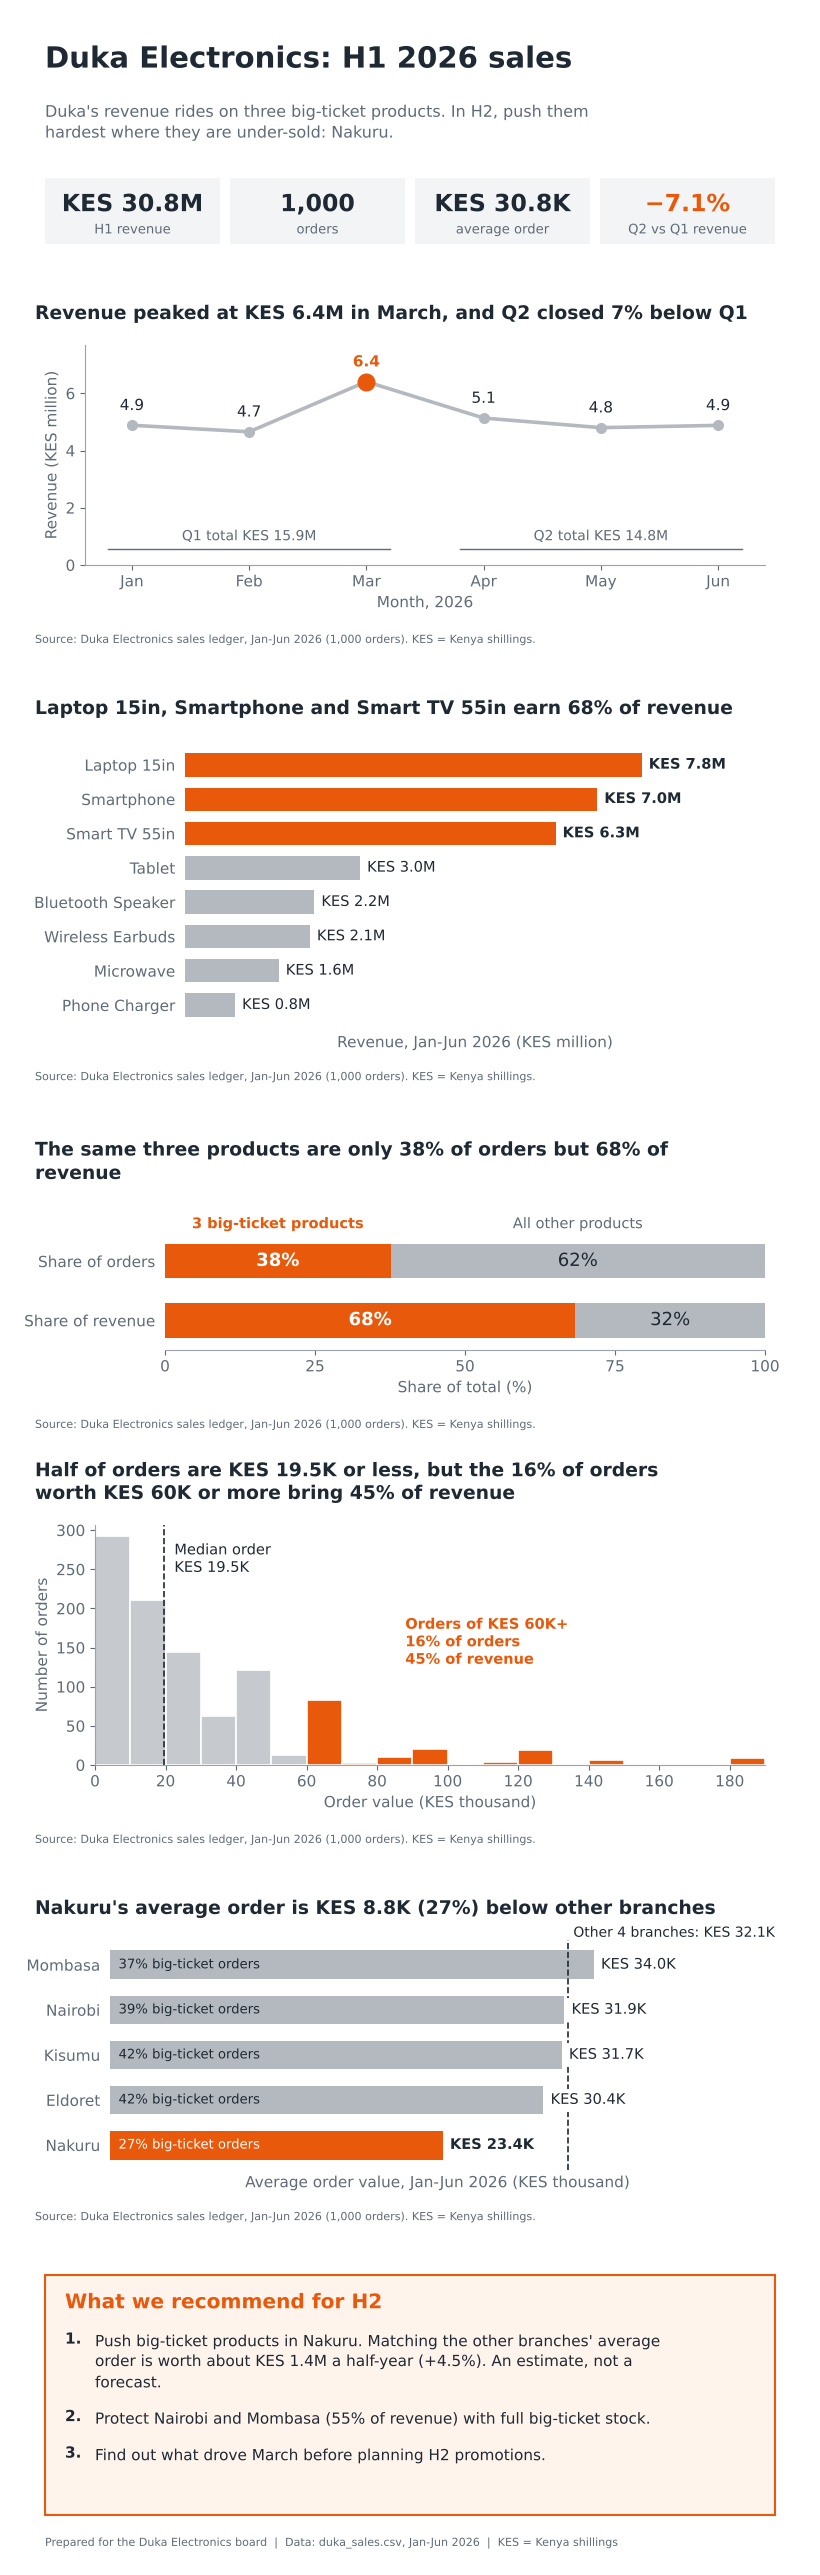

In [12]:
BIG_IDEA = ("Duka's revenue rides on three big-ticket products. In H2, push them hardest "
            "where they are under-sold: Nakuru.")

RECS = [
    f"Push big-ticket products in {K['weak_branch']}. Matching the other branches' average order is worth "
    f"about {kes_m(K['uplift'])} a half-year (+{K['uplift'] / K['total'] * 100:.1f}%). An estimate, not a forecast.",
    f"Protect Nairobi and Mombasa ({K['nairobi_mombasa_share']:.0f}% of revenue) with full big-ticket stock.",
    f"Find out what drove {K['peak_month']} before planning H2 promotions.",
]

order = ["trend", "products", "composition", "distribution", "branch"]
HEADER_H, REC_H = 2.6, 2.95
H = HEADER_H + sum(panel_height(PANELS[n][1]) for n in order) + REC_H

fig = plt.figure(figsize=(W, H))

# ---- header canvas: whole figure, coordinates in inches from the top-left ----
cv = fig.add_axes([0, 0, 1, 1]); cv.set_xlim(0, W); cv.set_ylim(H, 0); cv.axis("off")
cv.text(0.35, 0.50, "Duka Electronics: H1 2026 sales", fontsize=21, fontweight="bold", color=DARK, va="center")
cv.text(0.35, 0.92, textwrap.fill(BIG_IDEA, 72), fontsize=11.5, color=MID, va="top", linespacing=1.3)

kpis = [(kes_m(K["total"]), "H1 revenue", DARK), (f"{K['orders']:,}", "orders", DARK),
        (kes_k(K["aov"]), "average order", DARK), (f"{K['q_chg']:+.1f}%".replace("-", "\u2212"), "Q2 vs Q1 revenue", HIGHLIGHT)]
cw, gap, y0 = 1.75, 0.10, 1.68
for i, (val, lab, col) in enumerate(kpis):
    x0 = 0.35 + i * (cw + gap)
    cv.add_patch(plt.Rectangle((x0, y0), cw, 0.66, fc="#F3F4F6", ec="none"))
    cv.text(x0 + cw / 2, y0 + 0.27, val, ha="center", va="center", fontsize=17, fontweight="bold", color=col)
    cv.text(x0 + cw / 2, y0 + 0.52, lab, ha="center", va="center", fontsize=9.5, color=MID)

# ---- the five chart panels ----
top = HEADER_H
for name in order:
    fn, h, left = PANELS[name]
    fn(add_panel(fig, top, h, left))
    top += panel_height(h)

# ---- recommendation box ----
cv.add_patch(plt.Rectangle((0.35, top + 0.05), W - 0.7, REC_H - 0.55, fc="#FFF4EC", ec=HIGHLIGHT, lw=1.5))
cv.text(0.55, top + 0.33, "What we recommend for H2", fontsize=14.5, fontweight="bold", color=HIGHLIGHT, va="center")
yy = top + 0.62
for i, r in enumerate(RECS, 1):
    wrapped = textwrap.fill(r, 76)
    cv.text(0.55, yy, f"{i}.", fontsize=11, fontweight="bold", color=DARK, va="top")
    cv.text(0.85, yy, wrapped, fontsize=11, color=DARK, va="top", linespacing=1.3)
    yy += 0.205 * (wrapped.count("\n") + 1) + 0.16
cv.text(0.35, H - 0.22, "Prepared for the Duka Electronics board  |  Data: duka_sales.csv, Jan-Jun 2026  |  KES = Kenya shillings",
        fontsize=8, color=MID, va="center")

fig.savefig("reports/duka_board_report.png", dpi=200, facecolor="white")
print(f"Saved reports/duka_board_report.png  ({W:.0f} x {H:.1f} in at 200 dpi = {int(W*200)} x {int(H*200)} px)")
plt.show()

## 6. Before and after: makeover of the "Revenue by product" chart
**Before** is what a default `seaborn` bar chart gives you. **After** is the production version used on the board page (Chart 2).

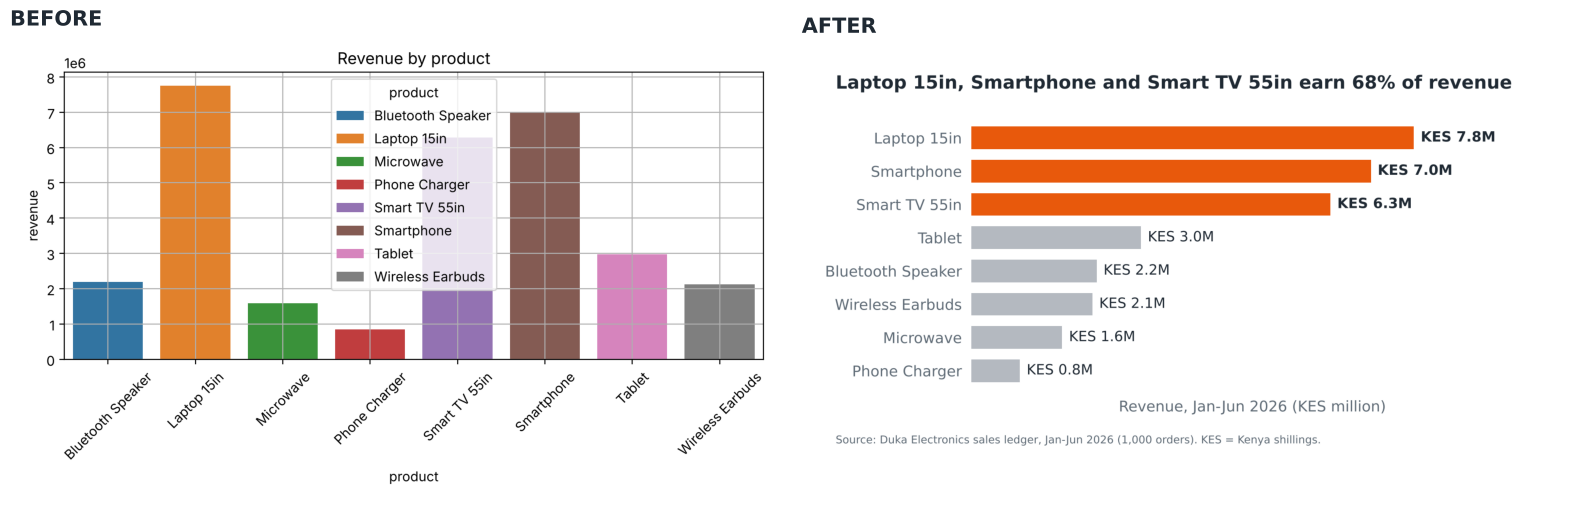

In [13]:
prod = df.groupby("product", as_index=False)["revenue"].sum()          # default order: alphabetical

# ---------- BEFORE: library defaults ----------
with plt.style.context("default"):
    fig, ax = plt.subplots(figsize=(8, 4.8))
    sns.barplot(data=prod, x="product", y="revenue", hue="product", palette="tab10", legend=True, ax=ax)
    ax.set_title("Revenue by product")
    ax.set_xlabel("product"); ax.set_ylabel("revenue")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(True)
    fig.tight_layout()
    fig.savefig("figures/before.png", dpi=200, facecolor="white")
    plt.close(fig)

# ---------- AFTER: the same data, redesigned ----------
fn, h, left = PANELS["products"]
fig = plt.figure(figsize=(W, panel_height(h)))
fn(add_panel(fig, 0, h, left))
fig.savefig("figures/after.png", dpi=200, facecolor="white")
plt.close(fig)

# ---------- side-by-side ----------
fig, axes = plt.subplots(1, 2, figsize=(16, 5.6))
for a, path, label in zip(axes, ["figures/before.png", "figures/after.png"], ["BEFORE", "AFTER"]):
    a.imshow(plt.imread(path)); a.axis("off"); a.set_title(label, fontsize=15, fontweight="bold", color=DARK, loc="left")
plt.tight_layout(); plt.show()

### What changed, and why

| # | Design change | Before | After | Why it helps a board member on a phone |
|---|---|---|---|---|
| 1 | **Sorted bars** | Alphabetical, so the ranking is hidden | Sorted largest to smallest | The answer to "what sells most?" is visible in one glance |
| 2 | **Horizontal layout** | Vertical bars with product names tilted 45° | Horizontal bars with readable names | Long names read naturally, with no head-tilting on a narrow screen |
| 3 | **One highlight colour** | Eight rainbow colours that mean nothing | Orange for the three products that carry the story, grey for the rest | Colour now carries information: it tells the eye where to look |
| 4 | **Direct labels, no legend** | A legend that repeats the x-axis, and an axis with `1e6` scientific notation | Value printed at the end of each bar (`KES 7.8M`), axis removed | No lookup between legend and bar, no mental maths |
| 5 | **Insight title, calculated in code** | "Revenue by product" (a label, not a message) | "Laptop 15in, Smartphone and Smart TV 55in earn 68% of revenue" | The title states the conclusion, and is built from the data so it can never go stale |
| 6 | **No chart junk** | Gridlines, boxed frame, tick marks, raw column names as axis labels | Gridlines, frame and ticks removed; plain-English axis label with units | Less ink, more signal; the unit (KES million) is no longer a guess |
| 7 | **Source line** | None | "Source: Duka Electronics sales ledger, Jan-Jun 2026 ... KES = Kenya shillings" | The reader knows where the numbers come from and what the currency is |

## 7. Sizing the H2 recommendation
The "KES 1.4M" figure assumes Nakuru keeps the same number of orders but its average order rises to the level of the other four branches. Because that is ambitious, here is what partial progress is worth.

In [14]:
sizing = pd.DataFrame({
    "Share of the gap closed": ["25%", "50%", "75%", "100% (peer level)"],
    "Nakuru average order (KES)": [K["weak_aov"] + f * K["aov_gap"] for f in (.25, .5, .75, 1)],
    "Extra revenue per half-year (KES)": [f * K["uplift"] for f in (.25, .5, .75, 1)],
}).round(0)
sizing["Uplift vs H1 revenue"] = (sizing["Extra revenue per half-year (KES)"] / K["total"] * 100).round(1).astype(str) + "%"
sizing.style.format({"Nakuru average order (KES)": "{:,.0f}", "Extra revenue per half-year (KES)": "{:,.0f}"}).hide(axis="index")

Share of the gap closed,Nakuru average order (KES),Extra revenue per half-year (KES),Uplift vs H1 revenue
25%,"25,567","346,239",1.1%
50%,"27,758","692,478",2.3%
75%,"29,949","1,038,716",3.4%
100% (peer level),"32,141","1,384,955",4.5%


**Caveats a senior analyst would flag:** (1) this is a what-if, not a forecast; (2) it assumes demand for big-ticket items exists in Nakuru, which should be tested with a pilot; (3) revenue is not profit, and big-ticket items carry lower margins and more stock risk, so margin data should be added before committing budget.

## 8. Board Summary (150 words)
Written from the calculated numbers, so it matches the charts. The word count is checked in code.

In [15]:
BOARD_SUMMARY = (
    f"Duka Electronics earned KES {K['total']/1e6:.1f}M from {K['orders']:,} orders in the first half of 2026. "
    f"Three big-ticket products ({join_names(K['top3'])}) are only {K['big_order_share']:.0f}% of orders "
    f"but {K['big_rev_share']:.0f}% of revenue, so the business depends on them.\n\n"
    f"Growth has stalled. Revenue peaked at KES {K['peak_value']/1e6:.1f}M in {K['peak_month']}, and the second "
    f"quarter closed {abs(K['q_chg']):.0f}% below the first. Half of all orders are worth KES "
    f"{K['median_order']/1e3:.1f}K or less, so a small number of large sales decides the result.\n\n"
    f"{K['weak_branch']} is the clearest gap. Its average order is KES {K['weak_aov']/1e3:.1f}K, against KES "
    f"{K['others_aov']/1e3:.1f}K across the other four branches, because only {K['weak_big_share']:.0f}% of its "
    f"orders are big-ticket.\n\n"
    f"We recommend three priorities for the second half. First, push big-ticket sales in {K['weak_branch']}, worth "
    f"about KES {K['uplift']/1e6:.1f}M if its average order reaches the peer level. Second, keep Nairobi and Mombasa, "
    f"{K['nairobi_mombasa_share']:.0f}% of revenue, fully stocked. Third, find out what drove {K['peak_month']} before planning promotions."
)
n_words = len(BOARD_SUMMARY.split())
print(f"Word count: {n_words}")
assert n_words == 150, "Board Summary must be exactly 150 words"
display(Markdown(BOARD_SUMMARY))
print("---BEGIN-SUMMARY---"); print(BOARD_SUMMARY); print("---END-SUMMARY---")

Word count: 150


Duka Electronics earned KES 30.8M from 1,000 orders in the first half of 2026. Three big-ticket products (Laptop 15in, Smartphone and Smart TV 55in) are only 38% of orders but 68% of revenue, so the business depends on them.

Growth has stalled. Revenue peaked at KES 6.4M in March, and the second quarter closed 7% below the first. Half of all orders are worth KES 19.5K or less, so a small number of large sales decides the result.

Nakuru is the clearest gap. Its average order is KES 23.4K, against KES 32.1K across the other four branches, because only 27% of its orders are big-ticket.

We recommend three priorities for the second half. First, push big-ticket sales in Nakuru, worth about KES 1.4M if its average order reaches the peer level. Second, keep Nairobi and Mombasa, 55% of revenue, fully stocked. Third, find out what drove March before planning promotions.

---BEGIN-SUMMARY---
Duka Electronics earned KES 30.8M from 1,000 orders in the first half of 2026. Three big-ticket products (Laptop 15in, Smartphone and Smart TV 55in) are only 38% of orders but 68% of revenue, so the business depends on them.

Growth has stalled. Revenue peaked at KES 6.4M in March, and the second quarter closed 7% below the first. Half of all orders are worth KES 19.5K or less, so a small number of large sales decides the result.

Nakuru is the clearest gap. Its average order is KES 23.4K, against KES 32.1K across the other four branches, because only 27% of its orders are big-ticket.

We recommend three priorities for the second half. First, push big-ticket sales in Nakuru, worth about KES 1.4M if its average order reaches the peer level. Second, keep Nairobi and Mombasa, 55% of revenue, fully stocked. Third, find out what drove March before planning promotions.
---END-SUMMARY---


## 9. Export a Looker Studio-ready file
The dashboard tells the same story on the same numbers. This writes a clean file with a `date_key` in `YYYYMMDD` format (the format Looker Studio recognises as a date), plus `revenue` and `price_band`.

In [16]:
looker = df.assign(
    order_date=df["order_date"].dt.strftime("%Y-%m-%d"),
    date_key=df["order_date"].dt.strftime("%Y%m%d"),
    month=df["month"].astype(str),
    weekday=df["order_date"].dt.day_name(),
)[["order_id", "order_date", "date_key", "month", "weekday", "branch", "product", "channel",
   "units", "unit_price", "revenue", "price_band"]]
looker.to_csv("data/duka_sales_clean.csv", index=False)
print(looker.shape, "-> data/duka_sales_clean.csv")
looker.head()

(1000, 12) -> data/duka_sales_clean.csv


,order_id,order_date,date_key,month,weekday,branch,product,channel,units,unit_price,revenue,price_band
0,DK0001,2026-01-01,20260101,2026-01,Thursday,Nakuru,Wireless Earbuds,In-store,1,6500,6500,Other
1,DK0002,2026-01-01,20260101,2026-01,Thursday,Nakuru,Bluetooth Speaker,Online,1,9500,9500,Other
2,DK0003,2026-01-01,20260101,2026-01,Thursday,Nairobi,Smartphone,In-store,2,22000,44000,Big-ticket
3,DK0004,2026-01-01,20260101,2026-01,Thursday,Nairobi,Tablet,In-store,3,18000,54000,Other
4,DK0005,2026-01-02,20260102,2026-01,Friday,Kisumu,Microwave,Online,1,15000,15000,Other
